<a href="https://colab.research.google.com/github/Nosimon-Nahar/LabReport-3_CSE-418/blob/main/Logical_operations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

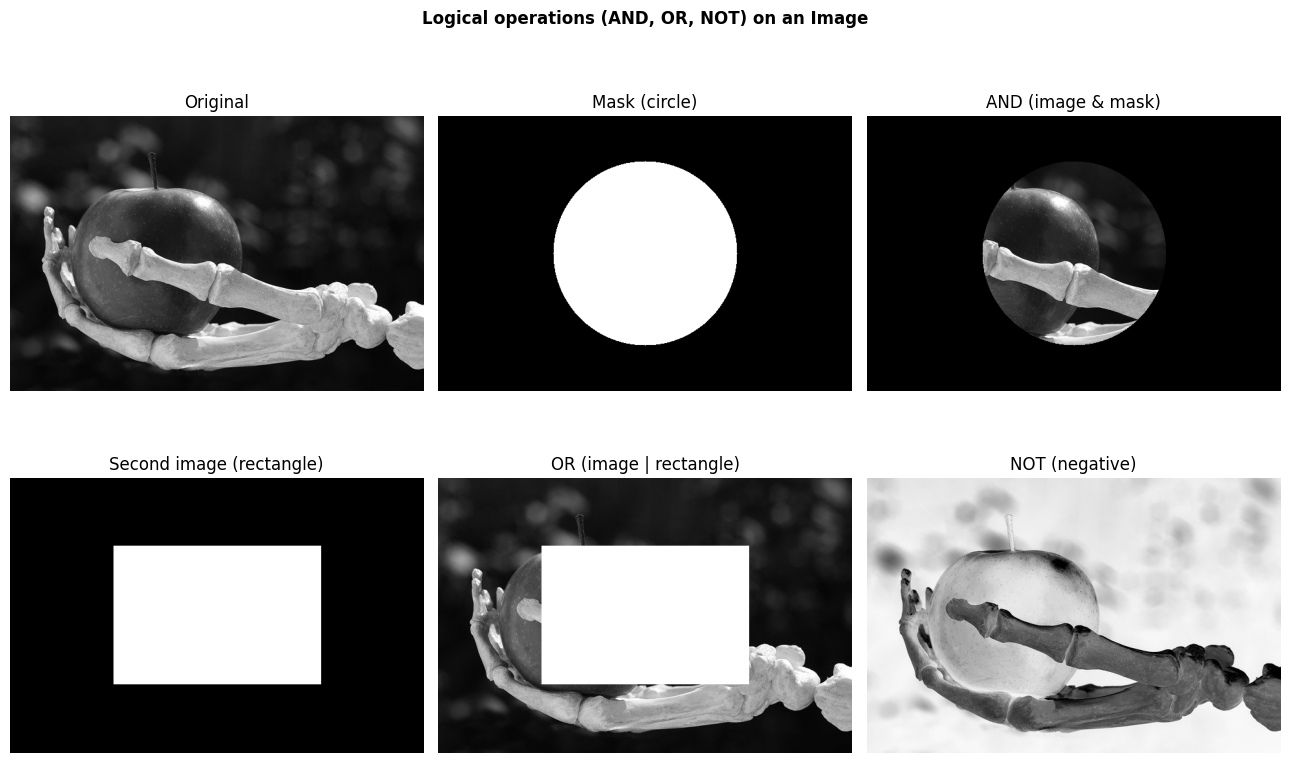

In [1]:
# AND, OR and NOT operations on an image
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt

def load_gray(path=None):
  # Load grayscale image; fall back to a synthetic test image.
    if path:
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            raise ValueError(f"Could not read image: {path}")
        return img
    x, y = np.meshgrid(np.linspace(0, 1, 512), np.linspace(0, 1, 512))
    img = 80 + 120 * x * y + 30 * np.sin(12 * y) * np.cos(8 * x)
    return np.clip(img, 0, 255).astype(np.uint8)

def main():
    img = load_gray("/content/images (4).jpg")
    h, w = img.shape

  # Mask 1: white filled circle on black background
    mask = np.zeros_like(img)
    cv2.circle(mask, (w//2, h//2), min(h, w) // 3, 255, -1)

  # Mask 2: white filled rectangle on black background
    rect = np.zeros_like(img)
    cv2.rectangle(rect, (w//4, h//4), (3*w//4, 3*h//4), 255, -1)

    and_res = cv2.bitwise_and(img, mask) # keeps image only where mask is white
    or_res = cv2.bitwise_or(img, rect)   # forces white where rectangle is white
    not_res = cv2.bitwise_not(img)       # negative: 255 - pixel

    images = [img, mask, and_res, rect, or_res, not_res]
    titles = ["Original", "Mask (circle)", "AND (image & mask)",
              "Second image (rectangle)", "OR (image | rectangle)", "NOT (negative)"]

    fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
    for ax, im, t in zip(axes.ravel(), images, titles):
        ax.imshow(im, cmap="gray", vmin=0, vmax=255)
        ax.set_title(t)
        ax.axis("off")
    fig.suptitle("Logical operations (AND, OR, NOT) on an Image", fontweight="bold")
    fig.tight_layout()
    fig.savefig("AND_OR_NOT_result.png", dpi=120)
    plt.show()

if __name__ == "__main__":
    main()